# Lesson 7 - Optimization

> ### Today's lesson
> * **Topic**: Optimization of functions of one variable.
> * **Mathematics (refresher)**: critical points, first and second derivatives, local and global extrema, saddle points.
> * **Python today**: `sympy.diff`/`sympy.solve`, `plt.annotate`, `scipy.signal.find_peaks`, `np.argmin`/`np.argmax`, list comprehensions.
> * **Remember**: Run the cells from top to bottom. If something behaves strangely: *Runtime → Restart session and run all*.


## Differentiation Recap
Differentiation rules are used in calculus (mathematics) to find the derivatives of different functions. To differentiate a function means finding a new function that describes the rate of increase of the original function.

A derivative is a mathematical concept from calculus, a branch of mathematics concerned with change and motion.

The derivative of a function represents the rate of change of the function at a specific point. It can be thought of as the slope of the tangent line to the function at that point. If the function represents a position with respect to time, then its derivative represents the velocity.

Mathematically, the derivative of a function at a point can be calculated as the limit of the change in the function's value divided by the change in input, as this change in input approaches zero.

The function that associates each point with its derivative is called the derivative function, or simply the derivative of the original function.

For example, if we have a function $f(x) = x^2$, then the derivative of this function is $2x$. This means that for any point $x$, the slope of the tangent line to the curve at that point is $2x$.

Derivatives play a key role in many fields of science and engineering, including physics, engineering, economics, and more, because they allow us to quantify and understand change.

# Optimization

Optimization is the process of finding the best possible outcome given a particular function and some constraints. In mathematics and economics, this is often a matter of maximizing or minimizing a given function.

For example, a company might try to maximize its profit given a certain output, or an engineer might try to minimize the amount of material used in a construction without compromising its strength.

Differentiation is used in this context to find local maxima and minima of functions, that is, points where the function switches from increasing to decreasing, or vice versa. This is done by finding the points where the function's derivative (or slope) is zero or does not exist. These points are candidates for local extrema (i.e., maxima or minima).

Let's take an example. Suppose a company has a profit function $P(x) = -2x^2 + 20x - 30$, where x represents the number of units produced and sold. The company wants to find the number of units that maximizes profit.

First, we differentiate the profit function to find its derivative: $P'(x) = 20 -4x$.

Next, we set this derivative equal to zero and solve for $x: -4x + 20 = 0$ gives $x = 5$.

This point is a critical point for the profit function, and by analyzing the derivative (or by applying the second-derivative test, if we have a function that is differentiable more than once), we can determine whether this point is a maximum or minimum. In this case, since the derivative is decreasing for values greater than 5, $x = 5$ is a maximum for the profit function.

So, by using differentiation, we have found that the company maximizes its profit by producing and selling 5 units.

As we have seen before, this can also be solved in Python. In the following example, we will differentiate the profit function, set it equal to zero, and solve for x:

* We start by importing the necessary packages, and defining $x$ as a symbol along with our function, $P$.

In [1]:
from sympy import symbols, diff, solve
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

In [2]:
# Define the variable
x = symbols('x')

In [3]:
# Define the profit function
P = -2*x**2 + 20*x - 30

In SymPy, when we use the **solve** function on an equation, it will try to find all the values of the unknown variable (in this case $x$) that satisfy the equation.

If we have a function $f(x)$ and its derivative $f′(x)$, then **solve(f_prime, x)** will give the values of $x$ where $f′(x)=0$. These are the critical points of the function, where it has either a local minimum, a local maximum, or an inflection point.

In mathematical analysis and calculus, a "critical point" of a function refers to a point where the first derivative $ f'(x) $ is either zero ($ f'(x) = 0 $) or does not exist. It is at these points that the function has the potential to have a local maximum, a local minimum, or a horizontal tangent (i.e., a "flat" spot on the curve).

**Why we solve $f'(x) = 0$**:

When we differentiate a function $ f(x) $, we get its first derivative $ f'(x) $, which represents the slope of the tangent to the curve at a specific point $ x $. If $ f'(x) = 0 $, it means that the tangent to the curve at this point is horizontal. This indicates a possible local maximum or minimum value of $ f(x) $.

For example, if we have a function $ f(x) = x^2 $, the first derivative will be $ f'(x) = 2x $. When we solve $ f'(x) = 0 $, we get $ x = 0 $, which is the critical point. If we plot $ f(x) = x^2 $, we will see that it is at this point the function has its minimum.

This is done in Python using these steps

* **Differentiate the function**: First, we take the first derivative of the function $ f(x) $, which gives $ f'(x) $.
* **Solve for critical points**: Then we solve $ f'(x) = 0 $ to find the values of $ x $ where $ f'(x) $ is zero. These $ x $-values are the critical points.
* (In some situations) **Check the second derivative**: To find out whether the critical points are local minima or maxima, we can use the second derivative $ f''(x) $. If $ f''(x) > 0 $ at a critical point, we have a local minimum. If $ f''(x) < 0 $, we have a local maximum.

So, when we see the expression "Solve $ f'(x) = 0 $", it is about finding these critical points, where the function potentially has a local maximum or minimum.

Starting from our example function $P(x) = -2x^2 + 20x - 30$, we can now follow these steps:

In [4]:
# Find the derivative
P_prime = diff(P, x)

In [5]:
P_prime

20 - 4*x

In [6]:
# Find the x-value(s) where the derivative is 0 (critical point(s))
critical_points = solve(P_prime, x)

In [7]:
print(f"Critical points: {critical_points}")

Critical points: [5]


In [8]:
# Find the second derivative
P_double_prime = diff(P_prime, x)

In [9]:
P_double_prime

-4

In [10]:
# Output as a symbol (in SymPy format)
test = P_double_prime.subs(x, 5)

In [11]:
test

-4

In [12]:
# Evaluate the second derivative at the critical point - with output as a numeric value (using evalf())
second_derivative_test = P_double_prime.evalf(subs={x: critical_points[0]})

In [13]:
second_derivative_test

-4.00000000000000

**evalf()** is a method in SymPy used to evaluate symbolic expressions numerically. When we use **evalf()** with **subs={x: critical_points[0]}**, we evaluate the second derivative of the profit function $P(x)$ at the first critical point found earlier in the code.

**evalf()** makes it possible to take a symbolic expression and evaluate it numerically at a given value of the variable. In this case, it is used to carry out the second-derivative test at the critical point we have found. It is not strictly necessary here, but there can be situations where the derivative test or second-derivative test is displayed as a symbolic value (e.g. the derivative of the exponential function) - to make sure it can be read by numpy and matplotlib.pyplot we use evalf() to ensure numeric output.

We can also have Python print this test for us (if, for example, you have many critical points, or want to automate the output for reading). In this example we use an if/else (elif) condition - this could, for example, be combined with a for-loop if you had many critical points to test.

In [14]:
# If/else condition being tested:
if second_derivative_test < 0:
    print(f"x={critical_points[0]} is a maximum.")
elif second_derivative_test > 0:
    print(f"x={critical_points[0]} is a minimum.")
else:
    print("The second-derivative test is inconclusive.")

x=5 is a maximum.


elif is short for "else if" and is part of an **if-elif-else** control structure in Python. This structure is used to test multiple conditions in sequence and execute a block of code when the first true condition is found.

In the example above we see this if-elif-else structure applied to carry out the second-derivative test:

* The **if** block: if second_derivative_test < 0: tests whether the value of the second derivative is less than 0. If this is true, the associated block of code is executed (**print(f"x={critical_points[0]} is a maximum.")**), and the rest of the structure is ignored.
* The **elif** block: elif second_derivative_test > 0: tests whether the value of the second derivative is greater than 0, but only if the preceding if condition was not true. If this elif condition is true, the associated block of code is executed (**print(f"x={critical_points[0]} is a minimum.")**), and the rest of the structure is ignored.
* The **else** block: If none of the above conditions are true, the code in the else block is executed (**print("The second-derivative test is inconclusive.")**).

So to summarize:

* **if** tests the first condition.
* If the **if** condition is false, it moves on to **elif** and tests that condition.
* If both **if** and **elif** are false, the **else** block is executed.

Only one of these blocks will be executed, depending on which condition is true first. This is an efficient way to handle multiple conditions in an organized and easy-to-understand way.

In [15]:
# Identify P(5) - just to show that the next steps are correct.
P.subs(x, 5)

20

### Visualizing the critical point of the profit function
We continue with the data above to visualize the function, and plot our local/global maximum.

We use the same plotting method we have used in previous lectures, and combine sympy, numpy and matplotlib to plot the critical point of the function.

In [16]:
# Generate values for x
x_values = np.linspace(0, 10, 400)

#### For-loops and list comprehension: $y$-values from $x$-values
After generating our $x$-values, we need to substitute our symbolic $x$ in the function $P$ with our $x$-values, **x_values**. This can be done in several ways in Python, but generally it is done using either **for-loops** or **list comprehension**.

For-loops are generally simpler to learn, and most people will learn for-loops first, and then try list comprehension afterwards, but I have included the example anyway - you will not be expected to write list comprehension, but in the real world it is good to be able to, since it is optimized both in terms of writing space and efficiency.

List comprehension is a compact way to create lists in Python. It is a syntactic construct that makes it possible to generate a new list by applying a formula to each element of an existing collection (e.g. a list, a set, a string, etc.). This is often faster and more readable than using a for-loop to achieve the same result.

In the following example, **P_values** and **P_values2** are two different ways of achieving the same result in Python. The following steps are taken in both code cells
* We create a list named **P_values(2)**
* We substitute the symbol $x$ in our $P$ function with our generated $x$-values, **x_values**, and assign them to our list, **P_values(2)**
* We convert our list into an array using NumPy's array() function.
* We have thus generated our $y$-values matching the given $x$-values.



In [17]:
from IPython.display import display, Image

display(Image(url='https://media.tenor.com/ZZ7lLVO1zZMAAAAC/surprise-tool-mickey-mouse.gif', width=1200, height=800))

##### Example 1: With list comprehension

In [18]:
#Example 1: With list comprehension

# Substitute x with x_values in our function, P. Here we use sympy's .subs() function to substitute the symbol x with our list of x-values
P_values = np.array([P.subs(x, x_val) for x_val in x_values])

In [19]:
P_values[:5]

array([-30, -29.5000031406838, -29.0025188283993, -28.5075470631466,
       -28.0150878449256], dtype=object)

##### Example 2: With for-loop

In [20]:
#Example 2: With for-loop

# With for-loop (more transparent, but also with more steps than with list comprehension)
P_values2 = []

for x_val in x_values:
  P_subs = P.subs(x, x_val)
  P_values2.append(P_subs)

# Converted to array
P_values2 = np.array(P_values2)

In [21]:
P_values2[:5]

array([-30, -29.5000031406838, -29.0025188283993, -28.5075470631466,
       -28.0150878449256], dtype=object)

#### Matplotlib for plotting, marking, and annotating
Now that we have generated our $x$- and $y$-values, we can visualize the function's maximum. We spend a bit of effort here visualizing this - for the uninitiated reader - what is happening in the plot.

In this example we introduce matplotlib's annotation function, in addition to the plotting approach we have used before.
* Define the figure size (10, 6)
* Plot our defined $x$- (**x_values**) and $y$-values (**P_values**), and give the function a label
* Mark the critical point by placing a dot (using scatter()) - we can find the critical point using our calculation, **critical_points**, and compute $y$ using SymPy's subs() function.
* Annotate the critical point with coordinates
  * plt.annotate() takes several different parameters (can be seen [here](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.annotate.html))
  * The first parameter is the text you want to insert in the annotation
  * The second parameter is the coordinates the annotation refers to.
  * The third parameter, **textcoords**, specifies where the text should be placed ("offset points" places the text right next to the point)



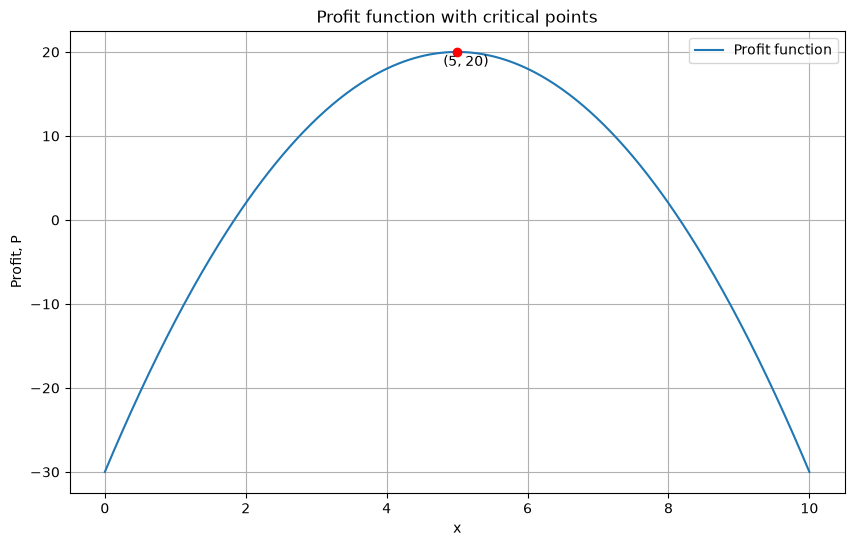

In [22]:
 # Plot the function
# Figure size
plt.figure(figsize=(10, 6))

# Plot of P function
plt.plot(x_values, P_values, label='Profit function', zorder=2)

# Mark the maximum
plt.scatter(critical_points, P.subs(x, critical_points[0]), color='red', zorder=3)

#Annotate the maximum
plt.annotate(f'({critical_points[0]}, {P.subs(x, critical_points[0])})', (critical_points[0], P.subs(x, critical_points[0])), textcoords="offset points", xytext=(-10, -10))

#x- and y-labels
plt.xlabel('x')
plt.ylabel('Profit, P')

# Title
plt.title('Profit function with critical points')

# Legend
plt.legend()

# Grid
plt.grid(True)

# Show and finish plot
plt.show()

In this case, the output will be x=5 is a maximum., indicating that the company maximizes its profit by producing and selling 5 units.

A function can theoretically have an infinite number of critical points, depending on the nature and complexity of the function. A critical point is a place where a function's first derivative is zero or does not exist.

For a simple first-degree polynomial function, such as $f(x) = ax + b$, there are no critical points, since its derivative is constant (and not zero). For a second-degree polynomial function, such as $f(x) = ax^2 + bx + c$, there is a single critical point, which is the peak or trough of the parabola.

Higher-degree polynomial functions can have multiple critical points. For example, a cubic function, such as $f(x) = ax^3 + bx^2 + cx + d$, can have up to two critical points.

Non-polynomial functions, such as trigonometric, exponential, logarithmic, and other complex functions, can have an infinite number of critical points. For example, the function $f(x) = sin(x)$ has an infinite number of maxima and minima, located at every peak and trough of the sine wave.



### Calculating and visualizing functions with many critical points

In the following code we focus on identifying and visualizing local minima and maxima in a function with an infinite number of solutions. The code is about finding and visualizing critical points (local maxima and minima) on a sine wave. Here is a simple explanation:

* First we import the necessary libraries: matplotlib.pyplot to draw the graph, numpy to create a range of x-values, and find_peaks from scipy.signal to find the critical points.
* Then an interval of x-values between -2$\pi$ and 2$\pi$ is generated, and the y-values are calculated as sin(x).
* Now comes the interesting part: We use find_peaks to find local maxima and minima. We also use -y to find local minima, because find_peaks only finds local maxima.

**An honest note about `find_peaks`:** SymPy finds critical points *mathematically* from the expression itself. `find_peaks` does something different: it only looks at the numerical values we sampled and searches for peaks among exactly those points. Its answer therefore depends on how densely we sampled and on its settings — it is a numerical tool, not a replacement for calculus.
* Then we filter the x- and y-values that correspond to these local maxima and minima.
* Finally, the graph is drawn with the line for sin(x), marking the local maxima in red and local minima in yellow.

So essentially the code takes a complex mathematical idea and makes it very accessible: it shows where on a sine wave we find local maxima and minima. This could be a nice way to illustrate how companies might have different "highs and lows" over time, if their earnings follow a similar wave-shaped pattern.

In [23]:
# Define x as a range of values between -2*pi and 2*pi
x = np.linspace(-2*np.pi, 2*np.pi, 400)

# Define y as a sine function of x
y = np.sin(x)

In [24]:
# Find local maxima and minima using find_peaks from the scipy library
local_max_indices, throw_away = find_peaks(y)
local_min_indices, throw_away = find_peaks(-y)

In [25]:
# Default output from find_peaks
find_peaks(y)

(array([ 50, 249]), {})

In [26]:
# The output we are interested in
local_max_indices

array([ 50, 249])

The function **find_peaks** from scipy.signal returns two outputs. The first output is an array of index values where the local maxima are found in the original y-array. The second output is an empty dictionary in this case, which we are not interested in, so we send it to a variable we never use - here called `throw_away`. (Python programmers typically use the name `_` for this purpose, but in Jupyter `_` already has a meaning - it stores the most recent output - so we use a descriptive name to avoid confusion).

In our example, find_peaks(y) returns the array [50, 249]. This means there are local maxima in the y-array at indices 50 and 249. If we look at our x- and y-values, we can see that y[50] and y[249] will be the y-values corresponding to these local maxima, and x[50] and x[249] will be the corresponding x-values.

In [27]:
# x-element at index 50
x[50]

np.float64(-4.708452147485454)

In [28]:
# y-element at index 50
y[50]

np.float64(0.9999922506833704)

So, to find the actual $x$- and $y$-values for the local extrema, we do this:

In [29]:
# Local maximum
local_max_x = x[local_max_indices]
local_max_y = y[local_max_indices]

# Local minimum
local_min_x = x[local_min_indices]
local_min_y = y[local_min_indices]

And then we can plot our sine function with markers at local minimum and maximum, like this:

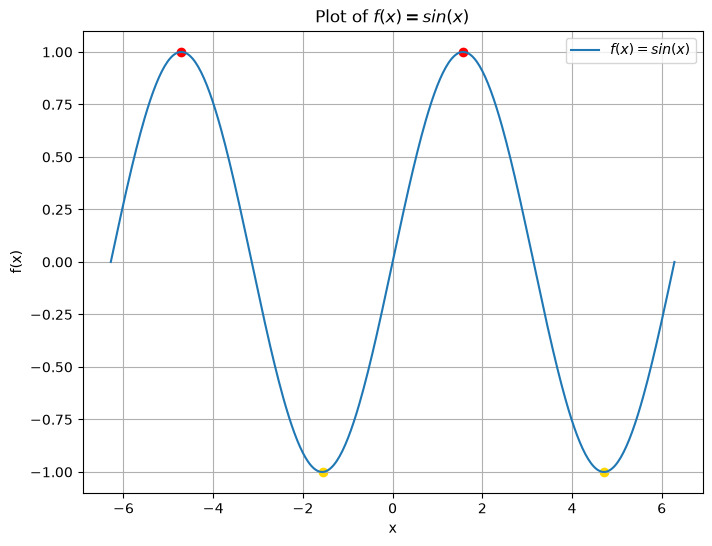

In [30]:
plt.figure(figsize=(8, 6))

plt.plot(x, y, label='$f(x) = sin(x)$')

plt.scatter(local_max_x, local_max_y, color='red')  # Mark the local maxima

plt.scatter(local_min_x, local_min_y, color='gold')  # Mark the local minima

plt.title('Plot of $f(x) = sin(x)$')

plt.xlabel('x')
plt.ylabel('f(x)')

plt.legend()

plt.grid(True)

plt.show()

In [31]:
from sympy import symbols, diff, solve, sin

# Define symbol and function
x = symbols('x')
f = sin(x)

In [32]:
# Find first and second derivative
f_prime = diff(f, x)
f_double_prime = diff(f_prime, x)

In [33]:
f_prime

cos(x)

In [34]:
f_double_prime

-sin(x)

In [35]:
# Find critical points
critical_points = solve(f_prime, x)

In [36]:
critical_points

[pi/2, 3*pi/2]

In [37]:
# Evaluate second derivative at the critical points
second_derivative_evaluated = [f_double_prime.evalf(subs={x: point}) for point in critical_points]

print("Critical points: ", critical_points)
print("Second derivative evaluated at the critical points: ", second_derivative_evaluated)

Critical points:  [pi/2, 3*pi/2]
Second derivative evaluated at the critical points:  [-1.00000000000000, 1.00000000000000]


In [38]:
critical_points[0].evalf()

1.57079632679490

### Critical points: $[ \frac{\pi}{2}, \frac{3\pi}{2} ]$

This output indicates that there are critical points at $ x = \frac{\pi}{2} $ and $ x = \frac{3\pi}{2} $ for the function $ f(x) = \sin(x) $ within one period of the sine wave. These points correspond to places where the first derivative $ f'(x) = \cos(x) $ equals 0.

### Second derivative evaluated at the critical points: $[-1, 1]$

This shows the value of the second derivative $ f''(x) $ at the critical points. The value of the second derivative can be used to determine whether a critical point is a minimum, maximum, or saddle point:

- $ f''(x) > 0 $ : Local minimum
- $ f''(x) < 0 $ : Local maximum
- $ f''(x) = 0 $ : Unknown (saddle point or flat region)

For $ f(x) = \sin(x) $:

- At $ x = \frac{\pi}{2} $, $ f''(x) = -1 $, which indicates a local maximum.
- At $ x = \frac{3\pi}{2} $, $ f''(x) = 1 $, which indicates a local minimum.

So these values indicate that there is a local maximum at $ \frac{\pi}{2} $ and a local minimum at $ \frac{3\pi}{2} $ within one period of the sine wave. These points repeat in every period of the function.



## Critical point without a local minimum or maximum
Remember that the presence of critical points does not necessarily mean there are local maxima or minima. To determine this, techniques such as the second-derivative test must be used.

A good example of a critical point that is neither a local minimum nor a maximum is a saddle point.

Take, for example, the function $f(x) = x^3$. If we take the derivative of this function, we get $f'(x) = 3x^2$. The derivative is 0 when $x = 0$, so $x = 0$ is a critical point of the function.

But looking at the function's behavior close to 0, $f(x)$ is actually increasing on *both* sides of $x = 0$ — the derivative $f'(x) = 3x^2$ is never negative. So instead of a local minimum or maximum, at $x = 0$ we have a point where the slope hits zero and then grows again, without a clear "valley" or "peak". Formally, in functions of one variable such a point is called a **stationary inflection point**; here we also use the broader term **saddle point**, which you may recognize.

We can visualize this with the following Python code:

In [39]:
# x as symbol
x = symbols('x')

#function
f = x**3

In [40]:
# Find the first and second derivative of f
f_prime = diff(f, x)
f_double_prime = diff(f_prime, x)

In [41]:
f_prime

3*x**2

In [42]:
f_double_prime

6*x

In [43]:
# Find the critical point by setting the first derivative equal to 0
critical_points = solve(f_prime, x)

In [44]:
critical_points

[0]

In [45]:
# Calculate the function's value at the critical point - if there are multiple critical points
f_critical_values = [f.subs(x, cp) for cp in critical_points]

In [46]:
# If there is only one critical point it would be fine to write it like this.
f_critical_values2 = f.subs(x, critical_points[0])

In [47]:
f_critical_values

[0]

In [48]:
# Evaluate the second derivative at the critical point - with output as a numeric value (using evalf())
second_derivative_test = f_double_prime.evalf(subs={x: critical_points[0]})

In [49]:
second_derivative_test

0

In [50]:
# Define x and y as numeric values
x = np.linspace(-2, 2, 400)
y = x**3

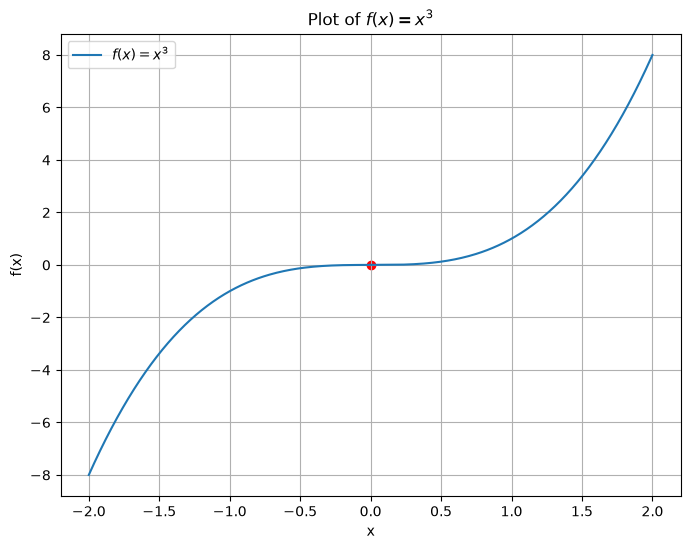

In [51]:
# plot function with marker at critical point (saddle point)

# Figure size
plt.figure(figsize=(8, 6))

#Plot of function
plt.plot(x, y, label='$f(x) = x^3$')

# Marker for critical point
plt.scatter(critical_points, f_critical_values, color='red')

#Title
plt.title('Plot of $f(x) = x^3$')

# x- and y-label
plt.xlabel('x')
plt.ylabel('f(x)')

# Legend
plt.legend()

# Grid
plt.grid(True)

# Show/finish plot
plt.show()

When we find the first derivative, which is $f'(x) = 3x^2$, we see that it is 0 when $x = 0$. But in this case it is not a local minimum or maximum, but rather a saddle point.

The reason $x=0$ is not a local minimum or maximum is because the function's behavior does not change from increasing to decreasing or vice versa at $x = 0$. For $x < 0$, $f(x)$ is negative, and for $x > 0$, $f(x)$ is positive. So the function changes from being negative to being positive at $x=0$, but there is no "peak" or "trough" at $x=0$, as there would be at a local maximum or minimum. Instead, the function passes smoothly through $x=0$, which is characteristic of a saddle point.

In [52]:
# If/else condition being tested:
if second_derivative_test < 0:
    print(f"x={critical_points[0]} is a maximum.")
elif second_derivative_test > 0:
    print(f"x={critical_points[0]} is a minimum.")
else:
    print(f"x={critical_points[0]} is a saddle point - or the test is inconclusive.")

x=0 is a saddle point - or the test is inconclusive.


## Note on global extrema
In more complex functions with a large dataset ($x$-values), it can be a bigger task to define global versus local extrema, but often you can use simple NumPy methods to assess the highest or lowest point of a function.

The functions **np.argmin** and **np.argmax** from the NumPy library return the index of the smallest/largest value in a given array. These functions are particularly useful when you need to find the position of the lowest/highest point in a numeric list or array, so you can refer to it later.

In [53]:
import numpy as np

array = np.array([10, 20, 5, 40, 30])
min_index = np.argmin(array)

print("Index of minimum value:", min_index)

Index of minimum value: 2


In [54]:
max_index = np.argmax(array)
print("Index of maximum value:", max_index)

Index of maximum value: 3
